In [1]:
%matplotlib inline
code_path='.'

## Audio Processing, Video Processing and Computer Vision
## Bachelor in Data Science and Engineering

# LAB SESSION 5: OBJECT DETECTION WITH CNNs


### Miguel Molina Moreno, Silvia Abal Fernández, María Loureiro Casalderrey, Miguel Ángel Fernández Torres


<center><img src='http://www.tsc.uc3m.es/~igonzalez/images/logo_uc3m_foot.jpg' width=400 /></center>

## Objectives

The main goal of this session is that the student investigates a Region-Convolutional Neural Network (R-CNN) that incorproates a Region Proposal Network (RPN) in the context of the object detection task. In other words, over a certain image, we will classify certain objects and their locations based on a set of predefined classes.

Particularly, we will work with Faster-RCNN [1], the first network to use an automatic strategy for region proposal. We will use part of the PASCAL VOC dataset to conduct our experiments.

## References

- [1] Faster-RCNN. https://arxiv.org/pdf/1506.01497
- [2] PASCAL VOC 2012 dataset. http://host.robots.ox.ac.uk/pascal/VOC/voc2012/index.html
- [3] https://github.com/sgrvinod/a-PyTorch-Tutorial-to-Object-Detection
- [4] https://tryolabs.com/blog/2018/01/18/faster-r-cnn-down-the-rabbit-hole-of-modern-object-detection/
- [5] Fast-RCNN y ROIPooling: https://arxiv.org/abs/1504.08083
- [6] https://en.wikipedia.org/wiki/File:RoI_pooling_animated.gif
- [7] FPN: https://arxiv.org/abs/1612.03144
- [8] https://jonathan-hui.medium.com/understanding-feature-pyramid-networks-for-object-detection-fpn-45b227b9106c

## Evaluation

An in-person evaluation of LS5: Other Applications of CNNs in Images will take place, together with the evaluation of LS6: Audio Analysis and Feature Extraction, in the the following date:

- Evaluation Lab 5 and Lab 6: **1st December 2026, 17:15-18:45**.

The evaluation of the LS5 practical assignment accounts for 1 point of the final course grade, same as the evaluation of LS5. I.e., the overall evaluation for LS5 and LS6 account for 2 points of the final course grade.

## Before we begin

Some previous steps need to be taken for the use of Google Colaboratory. The material of the lab needs to be unzipped into the Google Drive directory where this notebook is located. The name of this directory needs to be `objdetection`. Once this is done, the following code needs to be run after properly specifying the path to the directory (variable `path`):

In [2]:
#uncomment only if you plan to execute this in Google Colab
'''
from google.colab import drive
import os, sys
from shutil import copyfile

drive.mount('/content/drive')
print(os.getcwd())
code_path = 'YOUR_PATH' # <-- Full path prefix to objdetection dir
sys.path.append(code_path)

copyfile(code_path + '/myVOC4.zip', './myVOC4.zip') #Copy db files to our working folder

# Ignore warnings (when debugging, comment the next two lines)
import warnings
warnings.filterwarnings("ignore")
'''

'\nfrom google.colab import drive\nimport os, sys\nfrom shutil import copyfile\n\ndrive.mount(\'/content/drive\')\nprint(os.getcwd())\ncode_path = \'YOUR_PATH\' # <-- Full path prefix to objdetection dir\nsys.path.append(code_path)\n\ncopyfile(code_path + \'/myVOC4.zip\', \'./myVOC4.zip\') #Copy db files to our working folder\n\n# Ignore warnings (when debugging, comment the next two lines)\nimport warnings\nwarnings.filterwarnings("ignore")\n'

Now, we will decompress the dataset to a local folder to optimize data loading speed.

In [3]:
'''
#NOTE: Run this only once, in the machine where you want to run your code, then comment these lines
import zipfile
zipPath='./myVOC4.zip' #path of the 1st zip file
dataFolder='.' #We extract files to the current folder
with zipfile.ZipFile(zipPath, 'r') as zip_ref:
    zip_ref.extractall(dataFolder)
'''

"\n#NOTE: Run this only once, in the machine where you want to run your code, then comment these lines\nimport zipfile\nzipPath='./myVOC4.zip' #path of the 1st zip file\ndataFolder='.' #We extract files to the current folder\nwith zipfile.ZipFile(zipPath, 'r') as zip_ref:\n    zip_ref.extractall(dataFolder)\n"

Additionally, to run the code in a GPU environment (recommended) go to `Runtime->Change runtime type` and choose GPU in `Hardware accelerator`.

## Part 1. Theory

Before we learn how a Faster RCNN is implemented, let us remember some key aspects from the theory.

### Object detection

In object detection, an object is defined with respect to a _bounding box_, which completely surrounds the object. The bounding box is defined with respect to its location (usually its center or top-left coordinate) and its size (width and length). This means that 4 numbers are required to do so (see image below). Usually, the 4 coordinates are normalized by the image dimensions, so that they can take values in the range [0,1].

<img src="https://raw.githubusercontent.com/plasavall/detection_images/main/cs.PNG">

Each object will also have an associated label depending on which predefined category it belongs to.

### Faster-RCNN

This section will focus on some key concepts regarding Faster-RCNNs. However, it is highly recommended to review the original paper [1] and the course slides.

Faster-RCNN is a _framework_ that adapts a classification-oriented CNN to object detection. To do so, a _backbone_ is used consisting on the feature extraction layers of a pre-trained CNN. From this point, two  processing blocks are used to simultaneously infer an object location and its associated class. These blocks are a *Region Proposal Network (RPN)*, and a *RoI pooling* layer followed by a classification network (see image below).

<img src="https://raw.githubusercontent.com/plasavall/detection_images/main/faster.JPEG">

Thus, the specific layers in Faster RCNNs (after the backbone is run) work over a high-level feature map in which both the bounding boxes and the defining features have to be found. This feature map does not have the same size of the image, since strides>1 are used in the backbone layers that reduce the spatial dimension of the input tensor. In particular,  we define a global stride that indicates the accumulated spatial subsampling factor: e.g. if the size of the input image is H x W and the global stride is 16, then the high level feature map that goes to the RPN and Roi Pooling blocks is H/16 x W/16.


#### Region Proposal Network (RPN)

The main goal of this block is to obtain the areas of the image (or rather, of the feature maps) that are likely to contain an object. Therefore, we consider that each spatial location of the feature map may become the center of _k_ reference bounding boxes, known as _anchors_ in the algorithm. Typically, _k_>1, as we consider various sizes and aspect ratios (e.g. often, k=9, considering 3 sizes: 128, 256 and 512 pixels; and 3 aspect ratios 1:1, 1:2 and 2:1). An example of the anchors' locations and their representations can be seen in the images below.

<img src="https://raw.githubusercontent.com/plasavall/detection_images/main/anchor_centers.png">

<img src="https://raw.githubusercontent.com/plasavall/detection_images/main/anchors-progress.png">

From the amount of available anchors ($k \cdot H/16 \cdot W/16$), only some of them match the actual position and shape of the objects present in the image. Hence, the first task of the RPN, executed for each anchor, is to decide if the anchor is positive (it contains an object) or negative (it does not).

In order to train the corresponding layers in the RPN, we define a loss function $L_{objectness}$, which is a negative binary cross entropy between the out probabilities of the RPN and the labels. To provide the necessary ground truth labels, we rely on a metric called IoU - _Intersection over Union_ -, which stands for the intersection over union between the bounding box proposed by an anchor and the ground truth bounding box of an object. Anchors with a high IoU are labeled as positive (e.g. IoU>0.7), anchors with a low value (e.g. IoU<0.3) are labeled negative, whereas anchors with ambiguous values of IoU (e.g. 0.3<IoU<0.7) do not contribute to the training stage). See [1] for more details.

The number of sizes and shapes in the anchors, however, are limited by design and, hence, insufficient to represent the object's shape precisely. Thus, for the anchors considered as positive (those with high objectness score), the bounding box is then adjusted through a regression loss function $L_{reg}$, which aims to estimate the the difference between the real bounding box and the anchors' one. Therefore, the bounding box finally predicted by the RPN can be seen as a slight deviation of the original one proposed by the anchor.

<img src="https://raw.githubusercontent.com/plasavall/detection_images/main/reg.PNG">

In summary, $L_{objectness}$ finds the best anchors to represent the objects in the image while $L_{reg}$ adapts those anchors to the true shape of the object.


#### _RoI pooling_ and classification

Up to now, objects have been defined category-agnostically (without considering their class). Once the objects have been located, we need to determine their category. To do this, we need to crop the areas of the feature maps defined by the bounding boxes and pass them to a final set of fully-connected layers. However, this cannot be done directly, as it would require all crops to be the same size, which is almost always false. To address this issue, we use a *RoI pooling* strategy, which adapts the features map to a fixed size that can feed the subsequent layers.

This strategy simply consists on defining a grid over the feature map's bounding box (the ROI) which will be used to pool values from. The bounding box's size is $H_{bb}$ x $W_{bb}$, so if we set the grid to be $H_{fix}$ x $W_{fix}$ with each cell of the grid being size $H_{bb}/H_{fix}$ x $W_{bb}/W_{fix}$, we can apply a max pooling from each cell to obtain an adapted, fixed-sized representation of the feature map. This can be seen in the animation below.

<img src="https://raw.githubusercontent.com/plasavall/detection_images/main/RoI_pooling_animated.gif">

Once the fixed-sized representations are computed, we can use the network to classify the objects according to their category. The network is trained using a loss function $L_{cls}$. Additionally, the bounding boxes are refined with the newly obtained information (RoI pooling representation and class categorization) with a new regressive loss function $L_{reg2}$. An example of object detection for a certain input image is shown below (bounding box + object class with associated likelyhood).

<img src="https://raw.githubusercontent.com/plasavall/detection_images/main/result.PNG">


### Additional information for this lab: Feature Pyramid Network (FPN)

In object detection networks, detection object at different scales is challenging (particularly for small objects). The traditional strategy for this is the construction of a pyramid for the image at different scales (see the figure below), and the application of the same detection procedure at each scale. However, in the case of neural networks, the processing of different versions of the same image requires both memory and time. Alternatively, a more efficient multiscale processing can be applied to some intermediate feature representations obtained in the backbone network, as they will show notably smaller spatial dimensions.

<img src="https://raw.githubusercontent.com/plasavall/detection_images/main/pyramid.jpeg">

Note that feature maps near the input are not useful for especially large object detection, as they are composed of low-level structures (edges) of the image. For this reason, frequently, prior to an RPN, a *Feature Pyramid Network* (FPN) is applied, a feature extractor that generates feature maps of different spatial resolutions (thus multi-scale) with different information for each scale, like the figure below shows.

FPN composes of a bottom-up and a top-down pathway. The bottom-up pathway is the usual convolutional network for feature extraction. As we go up, the spatial resolution decreases. With more high-level structures detected, the semantic value for each layer increases.

FPN provides a top-down pathway to construct higher resolution layers from a semantic rich layer. While the reconstructed layers are semantic strong but the locations of objects are not precise after all the downsampling and upsampling. We add lateral connections between reconstructed layers and the corresponding feature maps to help the detector to predict the location betters. It also acts as skip connections to make training easier (similar to what ResNet does).

<img src="https://raw.githubusercontent.com/plasavall/detection_images/main/fpn.png">

On each of these feature maps, the RPN proposes the *anchors*. Specifically, depending on the spatial resolution of each feature map, the RPN uses different translation-invariant *anchors*: the RPN proposes the smallest-size translation-invariant *anchors* on the higher-resolution feature map (bottom layers of the backbone) and the largest translation-invariant *anchors* over the lower resolution map locations (top layers of the backbone). This makes sense from a logical point of view: on maps with more low-level information, the small *anchors* are placed to search for small objects, and on maps with high-level information, the larger *anchors* are placed, which look for objects that make up a large percentage of the image area.

For more detailed information, see [7].

### Evaluation for object detection

The performance of the detection system is analyzed in terms of the F1 score. However, to define this measure, we must first introduce the precision and the recall. Each of these measures are defined below.

The __precision__, for the case of object detection, represents the percentage of correctly detected objects out of the total number of detected objects (correct and incorrect). It is calculated as:

\begin{equation}
P=\frac{TP}{TP+FP},
\end{equation}

where $TP$ is the number of *true positives* (correctly identified objects) and $FP$ the number of *false positives* (incorrectly identified objects).

The __recall__ represents the percentage of correctly detected objects out of the total number of objects present in the images. It is calculated as:


\begin{equation}
R=\frac{TP}{TP+FN},
\end{equation}

where $ FN $ represents the number of *false negatives* (objects present in the images but not detected).


Nevertheless, the network provides a series of *bounding boxes* on the image that can overlap with the *ground truth* to a greater or lesser extent. Thus, we have to establish a __criterion to consider a prediction as correct__. This is usually established in the quality of segmentation, by means of the *Intersection over Union*, __IoU__ measure, also called *Jaccard Index* (JI). The $ IoU $ measures the similarity between two regions $A$ and $B$ as:

\begin{equation}
IoU=\frac{A \cap B}{A \cup B}
\end{equation}

where $\cap$ is the intersection between the regions (area in common) and $\cup$ is the union or total area that they cover between them. A minimum threshold of $IoU_{th} = 0.5 $ or $ IoU_ {th} = 0.7$ is usually set to consider a detection as correct. An example of the $ IoU $ measure on *bounding boxes* can be seen below (it will be used in our object detection architecture).

<img src="https://raw.githubusercontent.com/plasavall/detection_images/main/iou.png" width="500 pix">

Similarly, the $IoU$ measure can be used to set quality in object instance segmentation.

Finally, once these measures have been described, the F1 score can be defined. The F1-*score* considers both the precision and the recall to obtain a weighted harmonic mean between them such that:

\begin{equation}
F1=2\cdot \frac{P\cdot R}{P+R},
\end{equation}

Therefore, this measure summarizes in a single figure the performance of our object detector for a given __point of operation__. The network provides a series of *bounding boxes* with an associated __*score*__ and predicted category, which indicates how likely it is that an object of that certain class exists in that region. However, the precision, the recall and the F1 measure requires hard decisions, which will be generated depending  on the __operation point__ chosen for the system, namely an object detection threshold (defined as th_score later in the notebook).

### The definition of the object detection problem

The database that will be used in practice is a subset of the PASCAL VOC 2012 database [2]. This database contains images with various objects belonging to 20 categories:

- __Person__: _person_
- __Animal__: _bird, cat, cow, dog, horse, sheep_
- __Vehicle__: _aeroplane, bicycle, boat, bus, car, motorbike, train_
- __Indoor__: _bottle, chair, dining table, potted plant, sofa, tv/monitor_

During this session you are going to work on the set __Indoor__. Specifically, objects of the classes: _bottle, chair_, _sofa and _dining table_ will be detected. The images are provided in separate folders for training and testing. The sets are distributed as follows:
- Training: 234 images, in which there are 90 objects of the *bottle* class, 125 of the *chair* class, 36 of the *dining table* class and 40 of the *sofa* class.
- Test: 68 images, in which there are 36 objects of the *bottle* class, 52 of the *chair* class and 15 of the *dining table* class and 27 of the *sofa* class.

## Part 2. Implementation

First, we import the necessary libraries

In [4]:
import os
import numpy as np
import torch
import torch.utils.data
from PIL import Image, ImageFile, ImageDraw
import cv2
import random
import matplotlib.pyplot as plt
import pdb
# Set random seed for replicability (MANUALLY)
manualSeed = 999
print("Random Seed: ", manualSeed)
random.seed(manualSeed)
torch.manual_seed(manualSeed)
# torch uses some non-deterministic algorithms
torch.backends.cudnn.enabled = False

Random Seed:  999


### Runtime input variables

Some inputs are defined:

- **data_dir** - the root directory of the database, described later.
- **num_workers** - the number of threads to load the data with the DataLoader class.
- **batch_size** - the size of the _batch_.
- **num_classes** - the number of classes to detect.
- **class_names** - the names of the classes to detect.
- **num_epochs** - number of _epochs_ for network training.
- **step_size** - number of _epochs_ after which the learning rate is reduced by a factor of 0.1.
- **lr** - initial learning rate.
- **device** - the device (GPU or CPU) for execution.

In [5]:
data_dir = "myVOC4"
num_workers=2         # to debug, fix num_workers=0
batch_size = 1        # Training and test (if we use 1 we don't need to resize the images)
num_classes=5         # Number of classes
class_names=['background','bottle','chair','dining_table','sofa']
num_epochs = 6
step_size= 5
lr=0.001
# Detect if we have a GPU available
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(device)

cuda:0


### Modified library

For this session, a modified version of the torchvision library will be used, which we will name torchvision_05. This modified version allows to train our detection network with images that do not contain any objects, whereas the original version does not allow it. Likewise, it provides us with the information of the _anchors_ selected for each object during the inference. We import the necessary modules

In [6]:
import torchvision_05
from torchvision_05.models.detection.rpn import AnchorGenerator
from torchvision_05.models.detection.faster_rcnn import FastRCNNPredictor, FasterRCNN
from torchvision_05.models.detection.backbone_utils import resnet_fpn_backbone
import torchvision.transforms.functional as F

/usr/local/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


### Network

The network to be used follows the Faster-RCNN architecture using a ResNet-50 as backbone network. Specifically, the first 4 blocks of this network are used, composed of convolutional layers, batch normalization (whose parameters are frozen) and non-linear layers. We also add a FPN, _Feature Pyramid Network_, which extracts characteristics from the resulting maps of the network at different scales.

FPN composes of a bottom-up and a top-down pathway:

* The bottom-up pathway uses ResNet to construct the bottom-up pathway. It composes of many convolution modules (convi for i equals 1 to 5) each has many convolution layers. As we move up, the spatial dimension is reduced by 1/2 (i.e. double the stride). The output of each convolution module is labeled as Ci and later used in the top-down pathway.

* We apply a 1 × 1 convolution filter to reduce C5 channel depth to 256-d to create M5. This becomes the first feature map layer used for object prediction. As we go down the top-down path, we upsample the previous layer by 2 using nearest neighbors upsampling. We again apply a 1 × 1 convolution to the corresponding feature maps in the bottom-up pathway. Then we add them element-wise. We apply a 3 × 3 convolution to all merged layers. This filter reduces the aliasing effect when merged with the upsampled layer. We repeat the same process for P3 and P2. However, we stop at P2 because the spatial dimension of C1 is too large. Otherwise, it will slow down the process too much. Because we share the same classifier and box regressor of every output feature maps, all pyramid feature maps (P5, P4, P3 and P2) have 256-d output channels.

<img src="https://miro.medium.com/v2/resize:fit:720/format:webp/1*Hi3mCsgTEjPLtWnRyXx47w.jpeg">

After this *backbone*, Faster-RCNN's own modules are placed: the region proposition network and the _RoI pooling_ and classification.

<img src="https://miro.medium.com/v2/resize:fit:1100/format:webp/1*Wvn0WG4XZ0w9Ed2fFYPrXw.jpeg">

The following is the function that builds the network.

In [7]:
def get_model_detection(num_classes):
    # load a Faster RCNN model pre-trained on COCO
    model = torchvision_05.models.detection.fasterrcnn_resnet50_fpn(pretrained=True)

    # get number of input features for the classifier
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    # replace the pre-trained head with a new one
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

    return model

In the next cell, we will load the model, please stop to analyze each of the layers that define the model and its characteristics.

In [8]:
model_ft = get_model_detection(num_classes)
print(model_ft)
# Send the model to GPU
model_ft = model_ft.to(device)

FasterRCNN(
  (transform): GeneralizedRCNNTransform()
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): FrozenBatchNorm2d(64, eps=1e-05)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): FrozenBatchNorm2d(64, eps=1e-05)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): FrozenBatchNorm2d(64, eps=1e-05)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): FrozenBatchNorm2d(256, eps=1e-05)
          (relu): ReLU(inplace=True)
          (downsample): Sequential(
            (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False

### Database

The function to load the database is defined below. To simplify its treatment, the database is provided in the form of images (`images`) and masks for each of the object instances (` instances`). Thus, for each image there are as many masks as there are objects in it (with the segmentation of each one of them). Also, the category of each object is encoded in the name of the image. In addition, the `classes` semantic segmentation and the `masks` instance segmentation are provided.

Try to understand the return variables of this function.

**IMPORTANT**: input images are not normalized in this case. The _framework_ itself performs normalization internally with the mean of ImageNet samples.

In [9]:

class myVOCDataset(object):
    def __init__(self, root, train):
        self.root = root
        self.train = train
        # load all image files, sorting them to
        # ensure that they are aligned
        if (self.train):
            self.imgs = [os.path.join(root,name)
                 for root, dirs, files in os.walk(root)
                 for name in files if ('train'+os.path.sep+'images' in root)
                 if name.lower().endswith(".jpg")]
        else:
            self.imgs = [os.path.join(root,name)
                 for root, dirs, files in os.walk(root)
                 for name in files if ('test'+os.path.sep+'images' in root)
                 if name.lower().endswith(".jpg")]



    def __getitem__(self, idx):
        # load images ad masks
        img_path = self.imgs[idx]
        ImageFile.LOAD_TRUNCATED_IMAGES = True
        img = Image.open(img_path).convert("RGB")

        # Independent annotations for each object
        file=self.imgs[idx].split(os.path.sep)[-1]
        self.masks = [os.path.join(self.root,name)
                        for self.root, dirs, files in os.walk(self.imgs[idx].replace('images','instances').replace(file,''))
                        for name in files
                        if (name.startswith(file[:-4]+'_'))]
        if (not self.masks):
            masks=np.array(Image.new('L', img.size))
            labels=np.zeros((0,),dtype=np.int64)
            num_objs=0
        else:
            mask=np.zeros((len(self.masks),img.size[1],img.size[0]),dtype=np.uint8)
            labels=np.zeros((len(self.masks),),dtype=np.int64)
            for j in range(len(self.masks)):
                mask[j,:,:]=np.array(Image.open(self.masks[j]))
                labels[j]=int(self.masks[j].split('_')[-1][:-4])
            num_objs = len(mask)
            masks=np.asarray(mask)

        boxes = []

        for i in range(num_objs):
            pos = np.where(masks[i])
            xmin = np.min(pos[1])
            xmax = np.max(pos[1])
            ymin = np.min(pos[0])
            ymax = np.max(pos[0])
            # Get aspect ratio
            W=xmax-xmin
            H=ymax-ymin
            if (W==0 or H==0):
                labels=np.delete(labels,i)
            else:
                boxes.append([xmin, ymin, xmax, ymax])

        # convert everything into a torch.Tensor
        boxes = torch.as_tensor(boxes, dtype=torch.float32)
        num_objs = boxes.size(0)
        # get the labels
        labels = torch.as_tensor(labels, dtype=torch.int64)
        image_id = torch.tensor([idx])
        # We need the area to filter the empty images
        if (not boxes.size()==torch.Size([0])):
            area = (boxes[:, 3] - boxes[:, 1]) * (boxes[:, 2] - boxes[:, 0])
        else:
            area = torch.tensor([0.])

        target = {}
        target["boxes"] = boxes
        target["labels"] = labels
        target["image_id"] = image_id
        target["area"] = area

        img=F.to_tensor(img)
        return img, target, img_path

    def __len__(self):
        return len(self.imgs)

We use the previously defined function to load the data.

In [10]:
import utils

# use our dataset and defined transformations
dataset = myVOCDataset(data_dir, train=True)
dataset_test = myVOCDataset(data_dir, train=False)

# define training and test data loaders
data_loader = torch.utils.data.DataLoader(
    dataset, batch_size=batch_size, shuffle=True, num_workers=num_workers, # to debug, fix num_workers=0
    collate_fn=utils.collate_fn)

data_loader_test = torch.utils.data.DataLoader(
    dataset_test, batch_size=batch_size, shuffle=False, num_workers=num_workers,
    collate_fn=utils.collate_fn)

### Evaluation metrics

Likewise, the function that tests the quality of our model is defined in terms of object detection (precision and recall) and classification (among the detected objects, which ones are correctly classified according to their category).
The function receives as parameters:
- __model__: the CNN to evaluate.
- __dataloader__: the loader of the test data.
- __class_names__: names of the object classes to detect (always include the *background* class first).
- __th_score__: the network provides each detected object with a probability between 0 and 1. This threshold discards objects with objectness such that $Pr(object)<score_{th}$.
- __th_iou__: imposes a minimum IoU threshold from which to consider a detection as correct, that is, it is a decision on how to evaluate the system.
- __result_dir__: path to the results directory.
- __SAVE_OPT__: to save or not the test results as images with the *ground truth*, the predicted *bounding boxes* and the corresponding *anchors*.
- __SAVE_FULL__: to save the total results on each image (True) or save them in different folders for each size of *anchor* for later analysis (False).
- __VERBOSE__: prints on screen the total evaluation measures (without taking into account each class) if it is False, or the totals and marginals for each class if it is True.
- __batchsize__: must be equal to 1.

The function provides as outputs:
- __precision_RPN__ - Precision for object detection of the RPN.
- __recall_RPN__: the recall for the detection of RPN objects.
- __f1_score_RPN__: the F1 score for detection, which we take as the main measure of system performance.
- __cm_global__: confusion matrix between classes for classification.
- __prec_rec_global__: global precision and recall for the multiclass detection problem.
- __prec_rec_marginal__: per-class precision and recall for the multiclass detection problem.
- __total_anchors__: all the anchors of the network for the test set, for further analysis.
- __total_labels__: labels of said anchors.

__IMPORTANT:__ It should be noted that the inference function returns the evaluation measures for both the RPN (`precision_RPN`,` recall_RPN` and `f1_score_RPN`), that is, these measures refer to the *objectness* or ability to detect objects from the network regardless of its category; and the final detection scores of the network (`cm_global`,` prec_rec_global` and `prec_rec_marginal`). Of course, errors in RPN are also transfered to the global metrics, decreasing the performance.

In [11]:
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay, average_precision_score
from sklearn.preprocessing import LabelBinarizer

# Auxiliary function to compute the intersection over union between 2 bounding boxes
from external import bb_intersection_over_union

def test_detection_model(model, dataloader, class_names, th_score, th_iou, result_dir, SAVE_OPT, SAVE_FULL, VERBOSE, batch_size=1):
    since = time.time()
    # Standard values for anchors and image size
    bins=[48,96,192,384]
    size_anchors=[32,64,128,256,512]
    min_size = 800
    max_size = 1333
    model.eval()   # Set model to evaluate mode

    # Detection measurements
    ret = 0
    rel = np.zeros((len(class_names)-1,),dtype=int)
    ret_rel = np.zeros((len(class_names)-1),dtype=int)

    # Classification measurements
    y_true=np.zeros((0,),dtype='int')
    y_pred=np.zeros((0,),dtype='int')
    y_score=np.zeros((0,),dtype='int')
    batch_counter = 0
    total_anchors=np.zeros((0,4),dtype='float32')
    total_labels=np.zeros((0,),dtype=int)
    print('Evaluating...')
    with torch.no_grad():
        # Iterate over data.
        for inputs, targets, paths in dataloader:
            batch_counter = batch_counter + 1
            inputs = list(image.to(device) for image in inputs)
            labels = [{k: v.to(device) for k, v in t.items()} for t in targets]
            # Scale factor (useful for anchor extraction)
            size_img=inputs[0].size()[1:]
            scale_factor=min_size/min(size_img)
            if max(size_img) * scale_factor > max_size:
                scale_factor = max_size / max(size_img)
            # Let's create the ground-truth boxes and labels
            if (np.array(labels[0]['boxes'].cpu()).shape[0]==0):
                gt_boxes=np.zeros((0,4),dtype='float32')
            else:
                gt_boxes=np.array(labels[0]['boxes'].detach().cpu())
                gt_labels=np.array(labels[0]['labels'].detach().cpu())
                # Relevant objects per class
                for j in range(1,len(class_names)):
                    rel[j-1]=rel[j-1]+np.sum(gt_labels==j)
            # Prediction: returns boxes, scores (objectness), labels (class) and anchors
            pred = model(inputs)
            pred[0]['scores']=pred[0]['scores'].detach().cpu()
            pred[0]['boxes']=pred[0]['boxes'].detach().cpu()
            pred[0]['labels']=pred[0]['labels'].detach().cpu()
            pred[0]['anchors']=pred[0]['anchors'].detach().cpu()
            # We use only those with scores>th_score and convert them to numpy arrays
            if (len(pred[0]['scores'].numpy())==0):
                pred_boxes=np.zeros((0,4),dtype='float32')
                pred_labels=np.zeros((0,),dtype=int)
            else:
                pred_score = list(pred[0]['scores'].numpy())
                if (pred_score[0]>th_score):
                    pred_t = [pred_score.index(x) for x in pred_score if x>th_score][-1]
                    pred_class = [class_names[i] for i in list(pred[0]['labels'].numpy())]
                    pred_labels = pred[0]['labels'].numpy()
                    pred_boxes = [[i[0], i[1], i[2], i[3]] for i in list(pred[0]['boxes'].numpy())]
                    pred_boxes = np.array(pred_boxes[:pred_t+1])
                    pred_anchors = [[i[0], i[1], i[2], i[3]] for i in list(pred[0]['anchors'].numpy())]
                    pred_anchors = np.array(pred_anchors[:pred_t+1])
                    total_anchors = np.concatenate((total_anchors,pred_anchors),axis=0)
                    pred_class = pred_class[:pred_t+1]
                    pred_labels = pred_labels[:pred_t+1]
                    total_labels = np.concatenate((total_labels,pred_labels),axis=0)
                else:
                    pred_boxes=np.zeros((0,4),dtype='float32')
                    pred_labels=np.zeros((0,),dtype=int)


            # Retrieved objects
            ret=ret+len(pred_labels)
            assigned=np.zeros((pred_boxes.shape[0],),dtype='float')
            # Detection statistics: we compute the intersection over union between the ground-truth objects
            # and the retrieved ones, if it exceed th_iou, the detection is considered as a good one
            for j in range(gt_boxes.shape[0]):
                y_true=np.concatenate((y_true,gt_labels[j][np.newaxis]),axis=0)
                if pred_boxes.shape[0]>0:
                    ious=np.zeros((pred_boxes.shape[0],),dtype='float')

                    for k in range(pred_boxes.shape[0]):
                        ious[k]=bb_intersection_over_union(gt_boxes[j,:],pred_boxes[k,:])
                    iou_max=np.max(ious)
                    pos=np.argmax(ious)
                else:
                    iou_max=0
                if (iou_max>th_iou):
                    ret_rel[gt_labels[j]-1]+=1
                    y_pred=np.concatenate((y_pred,pred_labels[pos][np.newaxis]),axis=0)
                    assigned[pos]=1;
                else:
                    y_pred=np.concatenate((y_pred,np.zeros((1,))),axis=0)
            #else:
            #    y_pred=np.concatenate((y_pred,np.zeros((1,))),axis=0)

            #Now add non-assigned predictions as false detections to the statistics
            for k in range(pred_boxes.shape[0]):
                if assigned[k]==0:
                    y_true=np.concatenate((y_true,np.zeros((1,))),axis=0)
                    y_pred=np.concatenate((y_pred,pred_labels[k][np.newaxis]),axis=0)


            # Save the images with detections and ground-truth objects in a new folder, to analyze the results
            if SAVE_OPT and SAVE_FULL:
                aux=paths[0].split('/')
                folder_path=os.path.join(result_dir,'instances_pred_full')
                if not os.path.exists(folder_path):
                    os.makedirs(folder_path)
                img=np.array(F.to_pil_image(inputs[0].cpu()))
                for i in range(pred_boxes.shape[0]):
                    cv2.rectangle(img, (int(pred_boxes[i][0]),int(pred_boxes[i][1])), (int(pred_boxes[i][2]),int(pred_boxes[i][3])),color=(255, 0, 0), thickness=1)
                    cv2.putText(img,pred_class[i], (int(pred_boxes[i][0]),int(pred_boxes[i][1])), cv2.FONT_HERSHEY_SIMPLEX, 1, (255,255,255),thickness=1)
                for i in range(gt_boxes.shape[0]):
                    cv2.rectangle(img, (gt_boxes[i][0],gt_boxes[i][1]), (gt_boxes[i][2],gt_boxes[i][3]),color=(0, 255, 0), thickness=1)
                    cv2.putText(img,class_names[gt_labels[i]], (gt_boxes[i][0],gt_boxes[i][1]), cv2.FONT_HERSHEY_SIMPLEX, 1, (255,255,255),thickness=1)
                pred_path=folder_path+'/'+aux[-1]
                cv2.imwrite(pred_path,cv2.cvtColor(img, cv2.COLOR_RGB2BGR))
            elif SAVE_OPT and not SAVE_FULL:
                aux=paths[0].split('/')
                folder_path=os.path.join(result_dir,'instances_pred')
                if not os.path.exists(folder_path):
                    os.makedirs(folder_path)
                for i in range(pred_boxes.shape[0]):
                    anchor_size=size_anchors[np.digitize(np.sqrt((pred_anchors[i,2]-pred_anchors[i,0])*(pred_anchors[i,3]-pred_anchors[i,1])),bins)]
                    img=np.array(F.to_pil_image(inputs[0].cpu()))
                    cv2.rectangle(img, (int(pred_boxes[i][0]),int(pred_boxes[i][1])), (int(pred_boxes[i][2]),int(pred_boxes[i][3])),color=(255, 0, 0), thickness=1)
                    cv2.rectangle(img, (int(pred_anchors[i][0]/scale_factor),int(pred_anchors[i][1]/scale_factor)), (int(pred_anchors[i][2]/scale_factor),int(pred_anchors[i][3]/scale_factor)), color=(0, 0, 255), thickness=1)
                    cv2.putText(img,pred_class[i], (int(pred_boxes[i][0]),int(pred_boxes[i][1])), cv2.FONT_HERSHEY_SIMPLEX, 1, (255,255,255),thickness=1)
                    for j in range(gt_boxes.shape[0]):
                        cv2.rectangle(img, (int(gt_boxes[j][0]),int(gt_boxes[j][1])), (int(gt_boxes[j][2]),int(gt_boxes[j][3])),color=(0, 255, 0), thickness=1)
                        cv2.putText(img,class_names[gt_labels[j]], (int(gt_boxes[j][0]),int(gt_boxes[j][1])), cv2.FONT_HERSHEY_SIMPLEX, 1, (255,255,255),thickness=1)
                    if (not os.path.exists(os.path.join(folder_path,str(anchor_size)))):
                        os.makedirs(os.path.join(folder_path,str(anchor_size)))
                    pred_path=folder_path+'/'+str(anchor_size)+'/'+aux[-1][:-4]+'_'+str(i)+'.png'
                    cv2.imwrite(pred_path,cv2.cvtColor(img, cv2.COLOR_RGB2BGR))
            torch.cuda.empty_cache()

    # Detection statistics: precision and recall per class
    if (ret>0):
        precision_RPN=np.sum(ret_rel)/ret
    else:
        precision_RPN=0
    recall_RPN=np.zeros((rel.size,),dtype='float32')
    for j in range(rel.size):
        if (rel[j]>0):
            recall_RPN[j]=ret_rel[j]/rel[j]
        else:
            recall_RPN[j]=0
    # F1 score(weighted mean of precision and recall)
    if (np.mean(recall_RPN)==0 or precision_RPN==0):
        f1_score_RPN=0
    else:
        f1_score_RPN=2*np.mean(recall_RPN)*precision_RPN/(np.mean(recall_RPN)+precision_RPN)
    # Classification statistics: precision and recall
    prec_rec_marginal=precision_recall_fscore_support(y_true, y_pred, average=None,labels=[f for f in range(1,len(class_names))],zero_division=0)
    prec_rec_global=precision_recall_fscore_support(y_true, y_pred, average='macro',labels=[f for f in range(1,len(class_names))],zero_division=0)
    # Confusion matrix
    cm_global=confusion_matrix(y_true, y_pred, labels=None, sample_weight=None, normalize=None)
    time_elapsed = time.time() - since
    print('Evaluation complete in {:.0f}m {:.0f}s'.format(time_elapsed // 60, time_elapsed % 60))
    print('Objectness-RPN. F1: {:4f}.     Precision: {:4f}. Recall: {:4f}'.format(f1_score_RPN,precision_RPN,np.mean(recall_RPN)))
    if (VERBOSE):
        for i in range(1,len(class_names)):
            print('Class: ' + class_names[i]+'. Recall: {:1d}/{:1d}'.format(ret_rel[i-1],rel[i-1]))
        print('')
    if ((prec_rec_global[0]+prec_rec_global[1])>0):
        f1_class=2*prec_rec_global[0]*prec_rec_global[1]/(prec_rec_global[0]+prec_rec_global[1])
    else:
        f1_class=0
    print('Multi-class Detection: F1: {:4f}.     Precision: {:4f}. Recall: {:4f}'.format(f1_class,prec_rec_global[0],prec_rec_global[1]))
    if (VERBOSE):
        for i in range(1,len(class_names)):
            if ((prec_rec_marginal[0][i-1]+prec_rec_marginal[1][i-1])>0):
                f1_class=2*prec_rec_marginal[0][i-1]*prec_rec_marginal[1][i-1]/(prec_rec_marginal[0][i-1]+prec_rec_marginal[1][i-1])
            else:
                f1_class=0
            print('Class: ' + class_names[i]+'. F1: {:4f}.     Precision: {:4f}. Recall: {:4f}'.format(f1_class,prec_rec_marginal[0][i-1],prec_rec_marginal[1][i-1]))
    return (precision_RPN,recall_RPN,f1_score_RPN,cm_global,prec_rec_global,prec_rec_marginal,total_anchors,total_labels)

### Training

Training is performed during $n_e$ epochs, reducing the training error rate as training progresses. The code produces a file called _log.csv_ where the variation of the loss functions in each training _epoch_ can be analyzed, as well as the corresponding precision and recall in the test set for both detection and classification. Check that the loss functions decrease (approximately) monotonously, and that the test measures stagnate as the training progresses (and become louder).

__IMPORTANT:__ the best _epoch_ of the network is considered as the one that provides the best F1-score measure (harmonic mean of precision and recall) and its weights are stored.

In [12]:
import csv
from engine import train_one_epoch, eval_one_epoch
import time

# We create the baseline folder
result_dir=os.path.join(code_path,'baseline_results')
if not os.path.exists(result_dir):
    os.makedirs(result_dir)

# Weights for L_objectness, L_reg, L_cls y L_reg2
weights=[1,1,1,1]

# Training
# build an optimizer
params = [p for p in model_ft.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=lr,
                                momentum=0.9, weight_decay=0.0005)
# and a learning rate scheduler
lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer,
                                                step_size=step_size,
                                                gamma=0.1)

# CSV file for training results
if os.path.exists(os.path.join(result_dir,'log.csv')):
    os.remove(os.path.join(result_dir,'log.csv'))
csv_file=open(os.path.join(os.path.join(result_dir,'log.csv')),'w')
coord_writer = csv.writer(csv_file, delimiter=',', quotechar='"', quoting=csv.QUOTE_MINIMAL)
coord_writer.writerow(['Train total','Train rpn_box_reg','Train objectness','Train box_reg','Train classifier',
                        'Val total','Val rpn_box_reg','Val objectness','Val box_reg','Val classifier'])
best_f1=-0.0001
for epoch in range(num_epochs):
    print("Epoch: " + str(epoch+1) + "/" + str(num_epochs))
    if not os.path.exists(os.path.join(result_dir,'faster-rcnn-epoch{}.pth'.format(epoch))):
        #     train for one epoch, printing every epoch
        train_aux_losses=train_one_epoch(model_ft, optimizer, data_loader, device, weights, epoch, print_freq=250)
        # Update the learning rate
        lr_scheduler.step()
        # Validation
        val_aux_losses=eval_one_epoch(model_ft, data_loader_test, device, epoch, print_freq=250)
        # Save the losses
        coord_writer.writerow([str(train_aux_losses['total']),str(train_aux_losses['rpn_box_reg']),str(train_aux_losses['objectness']),
                                str(train_aux_losses['box_reg']),str(train_aux_losses['classifier']),
                                str(val_aux_losses['total']),str(val_aux_losses['rpn_box_reg']),str(val_aux_losses['objectness']),
                                str(val_aux_losses['box_reg']),str(val_aux_losses['classifier'])])
        # Evaluation
        [precision,recall,f1_score,cm,total,partial,_,_]=test_detection_model(model_ft, data_loader_test, class_names, 0.5,0.5, result_dir, False, False, False)
        # Save the state and the model with best AP-score for inference
        state = {'epoch': epoch + 1, 'state_dict': model_ft.state_dict(),
                  'optimizer': optimizer.state_dict(),
                  'scheduler':lr_scheduler.state_dict(),}
        torch.save(state, os.path.join(result_dir,'faster-rcnn-epoch{}.pth'.format(epoch)))
        if (f1_score>best_f1):
            torch.save(state, os.path.join(result_dir,'best_model.pth'.format(epoch)))
            best_f1=f1_score
    else:
        # Load this epoch information to resume training
        print("=> loading checkpoint '{}'".format(epoch))
        checkpoint = torch.load(os.path.join(result_dir,'faster-rcnn-epoch{}.pth'.format(epoch)))
        lr_scheduler.load_state_dict(checkpoint['scheduler'])
        model_ft.load_state_dict(checkpoint['state_dict'])
        optimizer.load_state_dict(checkpoint['optimizer'])
        print("=> loaded checkpoint '{}'" .format(epoch))

csv_file.close()

Epoch: 1/6
=> loading checkpoint '0'
=> loaded checkpoint '0'
Epoch: 2/6
=> loading checkpoint '1'
=> loaded checkpoint '1'
Epoch: 3/6
=> loading checkpoint '2'
=> loaded checkpoint '2'
Epoch: 4/6
=> loading checkpoint '3'
=> loaded checkpoint '3'
Epoch: 5/6
=> loading checkpoint '4'
=> loaded checkpoint '4'
Epoch: 6/6
=> loading checkpoint '5'
=> loaded checkpoint '5'


If the execution is halted mid-training for any reason, make sure to close the csv file that was opened (uncomment following cell).

In [13]:
# csv_file.close()

### Evaluation

After training the network, the results for the test set will be obtained. First, the trained model is loaded and the evaluation function is called. Pay attention to the parameters that the function receives.

Analyze the information that the function returns. Notice the difference between two performance metrics: a) the measures of *objectness* on the RPN and b) the system's object classification measures (over candidate bounding boxes considered as positive by the RPN).

In [14]:
# Inference
model_weights = torch.load(os.path.join(result_dir,'best_model.pth'.format(num_epochs-1)))['state_dict']
model_ft.load_state_dict(model_weights)
results=test_detection_model(model_ft, data_loader_test, class_names, 0.5, 0.5, result_dir, False, False, True)

Evaluating...


/tmp/ipykernel_2426/1938719830.py:41: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  if (np.array(labels[0]['boxes'].cpu()).shape[0]==0):
/tmp/ipykernel_2426/1938719830.py:44: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  gt_boxes=np.array(labels[0]['boxes'].detach().cpu())
/tmp/ipykernel_2426/1938719830.py:45: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword argument

Evaluation complete in 1m 6s
Objectness-RPN. F1: 0.643402.     Precision: 0.621429. Recall: 0.666987
Class: bottle. Recall: 22/36
Class: chair. Recall: 33/52
Class: dining_table. Recall: 8/15
Class: sofa. Recall: 24/27

Multi-class Detection: F1: 0.578043.     Precision: 0.580212. Recall: 0.575890
Class: bottle. F1: 0.666667.     Precision: 0.733333. Recall: 0.611111
Class: chair. F1: 0.504065.     Precision: 0.436620. Recall: 0.596154
Class: dining_table. F1: 0.437500.     Precision: 0.411765. Recall: 0.466667
Class: sofa. F1: 0.680000.     Precision: 0.739130. Recall: 0.629630


## Part 3. Experiments

Try to analyze the results and answer the proposed questions. This will help you to understand the functioning of this network in greater depth.



### 1. Baseline evaluation


Discuss why values of F1-score in Multiclass-detection are lower than those of Objectness-RPN.


> Answer here

RESPUESTA !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

In a two-stage detector like Faster R-CNN, object detection is performed sequentially: first, the **Region Proposal Network (RPN)** evaluates objectness and bounding-box localization in a class-agnostic manner (checking only the objectness score threshold and the $\text{IoU} > 0.5$ threshold against ground-truth boxes), and subsequently the **RoI Head classifier** assigns a specific category label to each proposed region.

In our baseline evaluation, **Objectness-RPN achieves an F1-score of `0.6434` (`Precision = 0.6214`, `Recall = 0.6670`)**, whereas **Multi-class Detection drops to an F1-score of `0.5780` (`Precision = 0.5802`, `Recall = 0.5759`)**. This degradation occurs because errors propagate in cascade from the RPN to the classifier:
1. **Correctly localized proposals misclassified (Case B):** Any object accurately localized by the RPN ($\text{IoU} > 0.5$, counting as a True Positive for the RPN) that is later assigned to `background` or to an incorrect object category by the classifier becomes a **False Negative** for its true class (and a **False Positive** for the wrongly predicted class). For example, in our test results, the RPN successfully localizes `24/27` `sofa` instances (`Recall = 0.8889`), but the classifier only identifies `17/27` correctly (`Recall = 0.6296`), meaning 7 well-localized sofas were misclassified. Similarly, `chair` drops from `33/52` to `31/52` and `dining_table` from `8/15` to `7/15`.
2. **Irrecoverable RPN misses (Case C):** Objects missed by the RPN (`False Negatives`) never reach the classifier, so the second stage cannot recover them.
3. **False background proposals (Cases D and E):** Region proposals generated over background regions (`False Positives` for the RPN) remain `False Positives` in multi-class detection whenever the classifier assigns them an object label instead of `background` (Case E).

Consequently, because the classifier adds a stricter semantic condition (`predicted_label == ground_truth_label`) on top of spatial localization, multi-class Precision and Recall—and therefore the **F1-score**—are lower than those of the RPN. *(Note: The only theoretical exception would occur if the RPN produced a very large number of background false alarms that the classifier successfully rejected as `background` [Case D], increasing multi-class precision enough to outweigh classification errors on true objects).*

Use the following code to show the confusion matrix and analyze it. Which class has more False Negatives? Which one has more True Positives? What does it mean?  

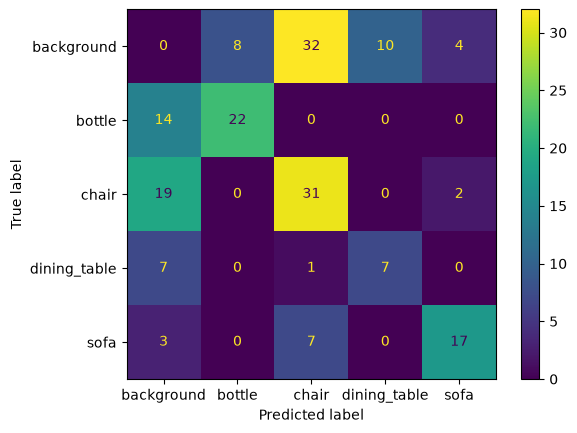

In [15]:
cm=results[3]
disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=class_names)
disp.plot()
plt.show()

ANALISIS !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

From the absolute confusion matrix, we observe the following counts across the 130 ground-truth test objects:
* **True Positives (diagonal):** **`chair`** has the highest number of True Positives (**31** out of 52 instances), followed by **`bottle`** (**22**/36), **`sofa`** (**17**/27), and **`dining_table`** (**7**/15).
* **False Negatives (sum of off-diagonal elements in each ground-truth row):** **`chair`** also accumulates the highest absolute number of False Negatives (**21** total: **19** missed detections assigned to `background` due to low score or $\text{IoU} \le 0.5$, plus **2** misclassified as `sofa`), followed by **`bottle`** (**14** FN), **`sofa`** (**10** FN: 3 missed + 7 misclassified as `chair`), and **`dining_table`** (**8** FN: 7 missed + 1 misclassified as `chair`).

**What does this mean?**

The fact that `chair` simultaneously exhibits the highest number of True Positives and the highest absolute number of False Negatives (as well as **32** background False Positives) is a direct consequence of **dataset class imbalance** and **intra-class variability**. In PASCAL VOC Indoor scenes, `chair` is the dominant category (125 training instances and 52 test instances, compared to only 36 training and 15 test instances for `dining_table`). Having more training examples enables the network to detect more chairs overall (high TP count), but chairs also appear in a wide variety of styles, scales, viewpoints, and partial occlusions (e.g., tucked under dining tables), leading to a high absolute count of missed instances and false alarms.

Now, use the following code to show the normalized confusion matrix and discuss the results. Why background class has a 0 in the diagonal? Without considering the background class, which classes are harder to distinguish for the detection model? Why?

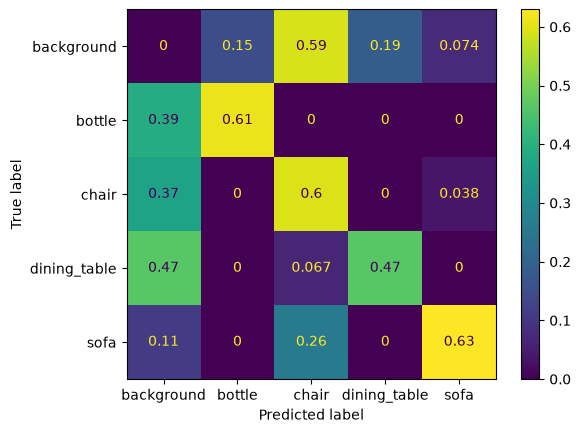

In [16]:
cm_global=results[3]
cm_global=cm_global/np.sum(cm_global,axis=1,keepdims=True)
disp=ConfusionMatrixDisplay(confusion_matrix=cm_global,display_labels=class_names)
disp.plot()
plt.show()

ANALISIS !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

* **Why does the `background` class have a `0` in the diagonal?**

  In object detection, background regions are not annotated as discrete ground-truth bounding boxes, so True Negatives (`TN`) over background are never counted. In `test_detection_model`, a ground-truth label `y_true = 0` (`background`) is recorded **only** when a predicted bounding box is left unassigned (`assigned[k] == 0`, i.e., a False Positive that either lies on background or has $\text{IoU} \le 0.5$ with all ground-truth objects) and carries a foreground predicted label `y_pred` $\in \{1, 2, 3, 4\}$. Because `y_pred` is never `0` when `y_true == 0`, the `(background, background)` diagonal cell is strictly `0`. Consequently, the top row shows the normalized distribution of the 54 False Positives across predicted classes (**59%** falsely predicted as `chair`, **19%** as `dining_table`, **15%** as `bottle`, and **7.4%** as `sofa`).

* **Excluding `background`, which classes are harder to distinguish and why?**

  The largest inter-class confusion occurs between **`sofa` and `chair`**: **26% (`0.26`)** of true `sofa` instances (7 out of 27) are misclassified as `chair`, while **3.8% (`0.038`)** of `chair` instances are misclassified as `sofa`. There is also minor confusion from **`dining_table` to `chair`** (**6.7% / `0.067`**), whereas `bottle` shows **0%** confusion with any other foreground category.
  
  This confusion happens because **`sofa` and `chair` share very similar visual features, materials, and structural parts** (upholstered cushions, backrests, and armrests). When a sofa is partially occluded, truncated by the image border, or viewed from an oblique angle, its apparent aspect ratio resembles an armchair (`chair`). Combined with the class imbalance favoring `chair` in the training set (125 vs. 40 instances), the classifier tends to bias ambiguous furniture proposals toward `chair`. *(Note: `dining_table` shows the lowest diagonal recall at **47%**, which is primarily caused by missed detections [`47%` falling into `background`] rather than confusion with other object categories).*

### 2. Influence of the threshold on the results

#### __*Objectness threshold*__

Analize the influence of the objectness score threshold on the results of the model. To this end, you can make use of the `test_detection_model` function to check three thresholds (0.3, 0.5, 0.7). Analyze the global precision, recall and F1-score values and discuss if they make sense.

You can also support your analysis with deeper insight (marginal inference can be shown through the `VERBOSE` parameter) and visual aid (use `SAVE_OPT` to that end).

Which threshold provides the best results? Do you think that this trade off between the thresholds and the metrics values is always the case for all object detection problems? Justify your answer.

In [17]:
# Include your code here
print('Threshold 0.3')
results=test_detection_model(model_ft, data_loader_test, class_names, 0.3, 0.5, result_dir, True, False, True)
!mv baseline_results/instances_pred baseline_results/instances_pred_0_3

# Include your code here
print('Threshold 0.5')
results=test_detection_model(model_ft, data_loader_test, class_names, 0.5, 0.5, result_dir, True, False, True)
!mv baseline_results/instances_pred baseline_results/instances_pred_0_5

# Include your code here
print('Threshold 0.7')
results=test_detection_model(model_ft, data_loader_test, class_names, 0.7, 0.5, result_dir, True, False, True)
!mv baseline_results/instances_pred baseline_results/instances_pred_0_7

Threshold 0.3
Evaluating...


/tmp/ipykernel_2426/1938719830.py:41: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  if (np.array(labels[0]['boxes'].cpu()).shape[0]==0):
/tmp/ipykernel_2426/1938719830.py:44: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  gt_boxes=np.array(labels[0]['boxes'].detach().cpu())
/tmp/ipykernel_2426/1938719830.py:45: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword argument

Evaluation complete in 1m 9s
Objectness-RPN. F1: 0.552774.     Precision: 0.424370. Recall: 0.792593
Class: bottle. Recall: 25/36
Class: chair. Recall: 39/52
Class: dining_table. Recall: 12/15
Class: sofa. Recall: 25/27

Multi-class Detection: F1: 0.492408.     Precision: 0.388979. Recall: 0.670762
Class: bottle. F1: 0.641026.     Precision: 0.595238. Recall: 0.694444
Class: chair. F1: 0.439024.     Precision: 0.321429. Recall: 0.692308
Class: dining_table. F1: 0.357143.     Precision: 0.243902. Recall: 0.666667
Class: sofa. F1: 0.485714.     Precision: 0.395349. Recall: 0.629630
Threshold 0.5
Evaluating...


/tmp/ipykernel_2426/1938719830.py:41: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  if (np.array(labels[0]['boxes'].cpu()).shape[0]==0):
/tmp/ipykernel_2426/1938719830.py:44: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  gt_boxes=np.array(labels[0]['boxes'].detach().cpu())
/tmp/ipykernel_2426/1938719830.py:45: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword argument

Evaluation complete in 1m 8s
Objectness-RPN. F1: 0.643402.     Precision: 0.621429. Recall: 0.666987
Class: bottle. Recall: 22/36
Class: chair. Recall: 33/52
Class: dining_table. Recall: 8/15
Class: sofa. Recall: 24/27

Multi-class Detection: F1: 0.578043.     Precision: 0.580212. Recall: 0.575890
Class: bottle. F1: 0.666667.     Precision: 0.733333. Recall: 0.611111
Class: chair. F1: 0.504065.     Precision: 0.436620. Recall: 0.596154
Class: dining_table. F1: 0.437500.     Precision: 0.411765. Recall: 0.466667
Class: sofa. F1: 0.680000.     Precision: 0.739130. Recall: 0.629630
Threshold 0.7
Evaluating...


/tmp/ipykernel_2426/1938719830.py:41: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  if (np.array(labels[0]['boxes'].cpu()).shape[0]==0):
/tmp/ipykernel_2426/1938719830.py:44: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  gt_boxes=np.array(labels[0]['boxes'].detach().cpu())
/tmp/ipykernel_2426/1938719830.py:45: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword argument

Evaluation complete in 1m 7s
Objectness-RPN. F1: 0.611077.     Precision: 0.758242. Recall: 0.511752
Class: bottle. Recall: 19/36
Class: chair. Recall: 27/52
Class: dining_table. Recall: 5/15
Class: sofa. Recall: 18/27

Multi-class Detection: F1: 0.545753.     Precision: 0.675772. Recall: 0.457692
Class: bottle. F1: 0.622951.     Precision: 0.760000. Recall: 0.527778
Class: chair. F1: 0.537634.     Precision: 0.609756. Recall: 0.480769
Class: dining_table. F1: 0.347826.     Precision: 0.500000. Recall: 0.266667
Class: sofa. F1: 0.666667.     Precision: 0.833333. Recall: 0.555556


> Answer here

RESPUESTA !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

#### 1. Summary of Quantitative Results (`th_iou = 0.5`)

| `th_score` | RPN Precision | RPN Recall | RPN F1 | Multi-class Precision | Multi-class Recall | Multi-class F1 |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **0.3** | 0.4244 | 0.7926 | 0.5528 | 0.3890 | 0.6708 | 0.4924 |
| **0.5** | 0.6214 | 0.6670 | **0.6434** | 0.5802 | 0.5759 | **0.5780** |
| **0.7** | 0.7582 | 0.5118 | 0.6111 | 0.6758 | 0.4577 | 0.5458 |

#### 2. Analysis of Precision, Recall, and F1-Score
The results clearly follow the expected **Precision–Recall trade-off** governed by the system's operating point (`th_score`):
* **Low threshold (`th_score = 0.3`):** Accepting low-confidence bounding boxes maximizes **Recall** (`0.7926` in RPN and `0.6708` in multi-class detection), recovering hard or partially occluded objects (e.g., `dining_table` reaches a multi-class recall of `0.6667`, detecting `12/15` in the RPN). However, this permissive threshold admits many noisy background proposals and duplicate detections around objects, causing **Precision** to drop sharply to `0.3890` (`0.2439` for `dining_table` and `0.3214` for `chair`), which penalizes the global **F1-score (`0.4924`)**.
* **Intermediate threshold (`th_score = 0.5`):** Filtering out weak proposals removes most background false alarms while retaining well-localized objects. Precision (`0.5802`) and Recall (`0.5759`) reach an equilibrium, yielding the highest global **F1-score (`0.5780`)**.
* **High threshold (`th_score = 0.7`):** Requiring high objectness confidence eliminates almost all false alarms, pushing multi-class **Precision** up to `0.6758` (`0.8333` for `sofa` and `0.7600` for `bottle`). However, valid objects with moderate confidence scores are discarded as False Negatives, dropping **Recall** to `0.4577` (especially for `dining_table`, whose recall falls to `0.2667` [`5/15` in RPN]) and reducing the global **F1-score** to `0.5458`.

#### 3. Optimal Threshold and Generalization to Other Object Detection Problems
* **Best threshold in this experiment:** **`th_score = 0.5`** provides the best overall performance, achieving both the highest **Multi-class F1-score (`0.5780`)** and the highest **Objectness-RPN F1-score (`0.6434`)**. Marginally, `bottle` (`0.6667`), `dining_table` (`0.4375`), and `sofa` (`0.6800`) all peak at `0.5`, while only `chair` peaks at `0.7` (`F1 = 0.5376`) because suppressing background false positives raises its precision from `0.4366` to `0.6098`.
* **Does this behavior generalize to all object detection problems?**
  While an **inverse relationship between Precision and Recall** when sweeping the confidence threshold is an inherent mathematical property of probabilistic detectors, **neither the optimal threshold value (`0.5`) nor the goal of maximizing the symmetric F1-score is universal**:
  1. **Model calibration and dataset complexity:** A model trained on larger datasets or with better confidence calibration may achieve its best F1 at higher thresholds (`0.7–0.8`), whereas under-confident models or domains with severe occlusion may require lower thresholds (`0.3–0.4`).
  2. **Application-specific error costs:** F1 weights Precision and Recall equally, which is not appropriate for every real-world task. **Safety-critical applications** (e.g., pedestrian detection in autonomous driving or medical lesion detection) prioritize **high Recall** (lower `th_score`) because missing a true object (FN) is far more dangerous than a false alarm (FP). Conversely, **automated quality control or high-precision indexing** prioritizes **high Precision** (higher `th_score`) to avoid acting on false detections.



#### __*IoU threshold*__

Analyze the influence of the IoU threshold on the results. To this end, you can make use of the `test_detection_model` function to check three thresholds (0.3, 0.5, 0.7). You can support your analysis with deeper insight (marginal inference can be shown through the `VERBOSE` parameter) and visual aid (use `SAVE_OPT` to that end).

In [18]:
# Include your code here
print('IoU_TH 0.3')
results=test_detection_model(model_ft, data_loader_test, class_names, 0.5, 0.3, result_dir, True, False, True)
!mv baseline_results/instances_pred baseline_results/instances_pred_iou_0_3

# Include your code here
print('IoU_TH 0.5')
results=test_detection_model(model_ft, data_loader_test, class_names, 0.5, 0.5, result_dir, True, False, True)
!mv baseline_results/instances_pred baseline_results/instances_pred_iou_0_5

# Include your code here
print('IoU_TH 0.7')
results=test_detection_model(model_ft, data_loader_test, class_names, 0.5, 0.7, result_dir, True, False, True)
!mv baseline_results/instances_pred baseline_results/instances_pred_iou_0_7

IoU_TH 0.3
Evaluating...


/tmp/ipykernel_2426/1938719830.py:41: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  if (np.array(labels[0]['boxes'].cpu()).shape[0]==0):
/tmp/ipykernel_2426/1938719830.py:44: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  gt_boxes=np.array(labels[0]['boxes'].detach().cpu())
/tmp/ipykernel_2426/1938719830.py:45: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword argument

Evaluation complete in 1m 8s
Objectness-RPN. F1: 0.720133.     Precision: 0.692857. Recall: 0.749644
Class: bottle. Recall: 25/36
Class: chair. Recall: 37/52
Class: dining_table. Recall: 10/15
Class: sofa. Recall: 25/27

Multi-class Detection: F1: 0.622748.     Precision: 0.620302. Recall: 0.625214
Class: bottle. F1: 0.757576.     Precision: 0.833333. Recall: 0.694444
Class: chair. F1: 0.564516.     Precision: 0.486111. Recall: 0.673077
Class: dining_table. F1: 0.437500.     Precision: 0.411765. Recall: 0.466667
Class: sofa. F1: 0.705882.     Precision: 0.750000. Recall: 0.666667
IoU_TH 0.5
Evaluating...


/tmp/ipykernel_2426/1938719830.py:41: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  if (np.array(labels[0]['boxes'].cpu()).shape[0]==0):
/tmp/ipykernel_2426/1938719830.py:44: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  gt_boxes=np.array(labels[0]['boxes'].detach().cpu())
/tmp/ipykernel_2426/1938719830.py:45: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword argument

Evaluation complete in 1m 8s
Objectness-RPN. F1: 0.643402.     Precision: 0.621429. Recall: 0.666987
Class: bottle. Recall: 22/36
Class: chair. Recall: 33/52
Class: dining_table. Recall: 8/15
Class: sofa. Recall: 24/27

Multi-class Detection: F1: 0.578043.     Precision: 0.580212. Recall: 0.575890
Class: bottle. F1: 0.666667.     Precision: 0.733333. Recall: 0.611111
Class: chair. F1: 0.504065.     Precision: 0.436620. Recall: 0.596154
Class: dining_table. F1: 0.437500.     Precision: 0.411765. Recall: 0.466667
Class: sofa. F1: 0.680000.     Precision: 0.739130. Recall: 0.629630
IoU_TH 0.7
Evaluating...


/tmp/ipykernel_2426/1938719830.py:41: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  if (np.array(labels[0]['boxes'].cpu()).shape[0]==0):
/tmp/ipykernel_2426/1938719830.py:44: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  gt_boxes=np.array(labels[0]['boxes'].detach().cpu())
/tmp/ipykernel_2426/1938719830.py:45: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword argument

Evaluation complete in 1m 8s
Objectness-RPN. F1: 0.457735.     Precision: 0.442857. Recall: 0.473647
Class: bottle. Recall: 19/36
Class: chair. Recall: 21/52
Class: dining_table. Recall: 5/15
Class: sofa. Recall: 17/27

Multi-class Detection: F1: 0.430445.     Precision: 0.438649. Recall: 0.422543
Class: bottle. F1: 0.575758.     Precision: 0.633333. Recall: 0.527778
Class: chair. F1: 0.325203.     Precision: 0.281690. Recall: 0.384615
Class: dining_table. F1: 0.312500.     Precision: 0.294118. Recall: 0.333333
Class: sofa. F1: 0.489796.     Precision: 0.545455. Recall: 0.444444


ANALISIS !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

#### 1. Summary of Quantitative Results (`th_score = 0.5`)

| `th_iou` | RPN Precision | RPN Recall | RPN F1 | Multi-class Precision | Multi-class Recall | Multi-class F1 |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **0.3** | 0.6929 | 0.7496 | **0.7201** | 0.6203 | 0.6252 | **0.6227** |
| **0.5** | 0.6214 | 0.6670 | 0.6434 | 0.5802 | 0.5759 | 0.5780 |
| **0.7** | 0.4429 | 0.4736 | 0.4577 | 0.4386 | 0.4225 | 0.4304 |

#### 2. Analysis of the Influence of `th_iou`
Unlike `th_score` (which alters the set of candidate boxes produced by the detector and trades Precision against Recall), keeping `th_score = 0.5` fixes the exact same set of predicted bounding boxes across all three runs. Instead, `th_iou` controls the **strictness of the spatial localization criterion** required to validate a prediction as a True Positive (`TP`):

* **Simultaneous drop in Precision and Recall as `th_iou` increases:** Moving from `th_iou = 0.3` to `0.5` and `0.7` causes **both Precision and Recall to decrease monotonically** (Multi-class F1 drops from `0.6227` $\rightarrow$ `0.5780` $\rightarrow$ `0.4304`). Whenever a predicted box has moderate spatial overlap with a ground-truth object (for instance, $0.5 \le \text{IoU} < 0.7$), raising `th_iou` to `0.7` invalidates that match, producing a **double penalty**:
  1. The ground-truth object is left unmatched, increasing **False Negatives (`FN`)** and lowering **Recall**.
  2. The valid-class predicted box remains unassigned (`assigned[k] == 0`), converting a former `TP` into a **False Positive (`FP`)** and lowering **Precision**.
* **Loose overlap (`th_iou = 0.3`):** Boxes with coarse bounding-box regression (such as partially occluded chairs or tables) are accepted as valid detections, boosting RPN F1 to `0.7201` and Multi-class F1 to `0.6227`. However, in practice, `0.3` is too permissive because a box covering less than a third of the object is considered a hit.
* **Strict overlap (`th_iou = 0.7`):** Requiring tight bounding-box alignment severely penalizes categories prone to occlusion and irregular boundaries. Specifically, `chair` F1 drops from `0.5041` (`th_iou = 0.5`) to `0.3252`, and `dining_table` drops from `0.4375` to `0.3125` (only `5/15` recalled in the RPN). Conversely, compact or clearly bounded objects such as `bottle` (`F1 = 0.5758`, `Precision = 0.6333`) and `sofa` (`F1 = 0.4898`) retain substantially better localization accuracy under strict IoU constraints.

### 3. Analysis of the anchor sizes

The images in the PASCAL VOC database have a maximum size of 500 pixels on their longest side and one smaller side of variable size, and therefore different aspect ratios. Note, however, that Pytorch scales images so that their minimum side measures 800 pixels or their maximum side 1333 (see the __resize__ function of __torchvision_05.models.detection.transform__).

The following code (when uncommented) calculates the distribution of sizes and aspect ratios of objects in the train and test datasets.

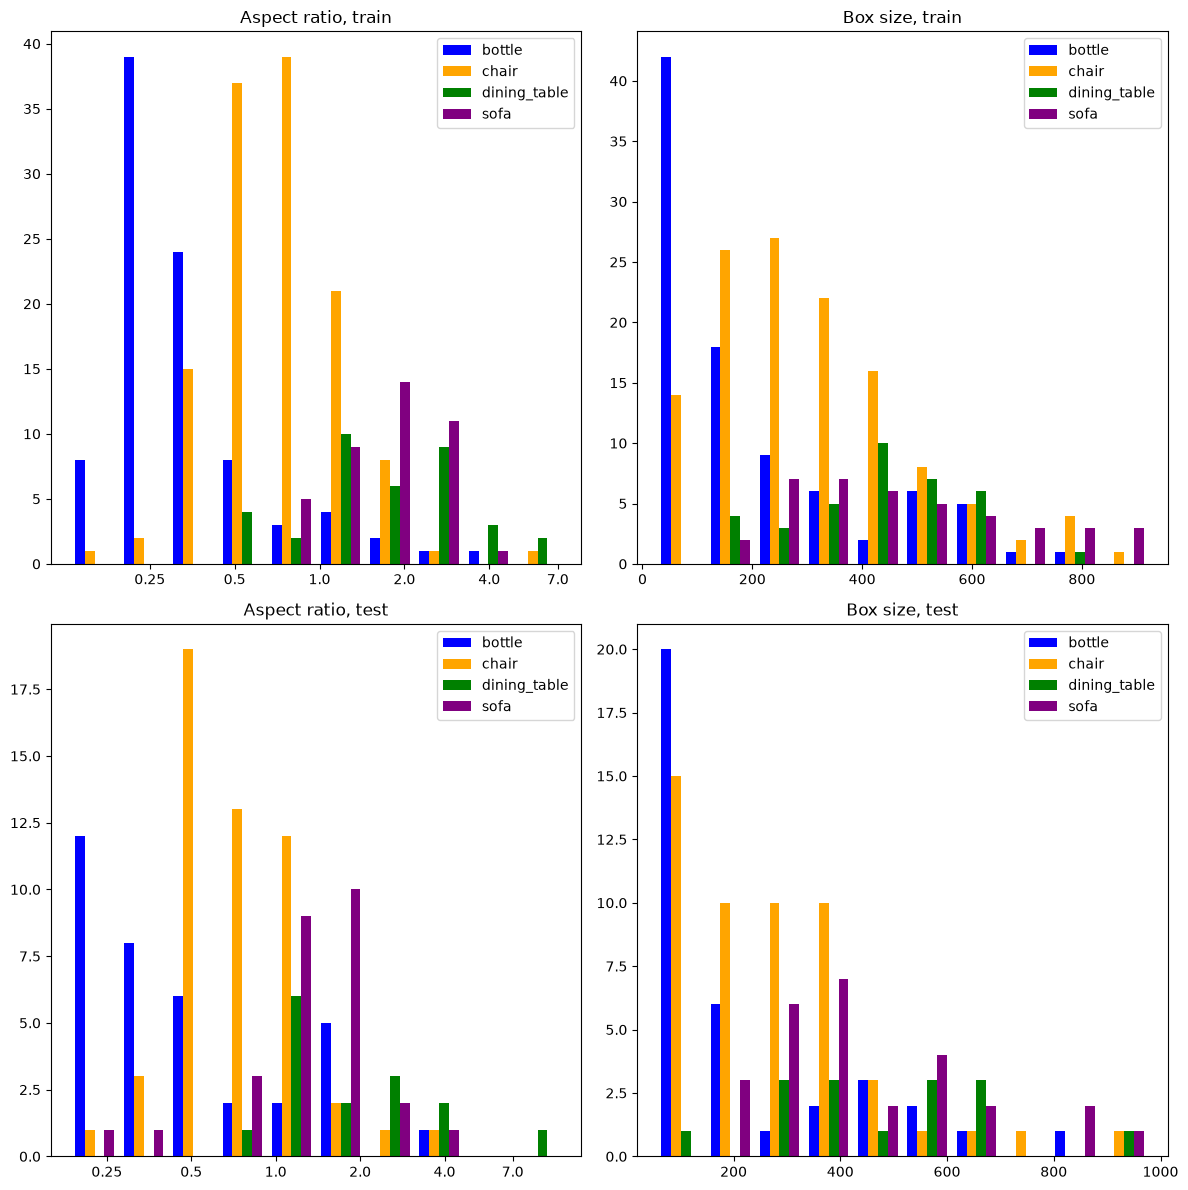

In [19]:
import matplotlib.pyplot as plt
from external import get_gt_anchors
# define training and test data loaders
data_loader_0 = torch.utils.data.DataLoader(
    dataset, batch_size=batch_size, shuffle=True, num_workers=0,
    collate_fn=utils.collate_fn)

data_loader_test_0 = torch.utils.data.DataLoader(
     dataset_test, batch_size=batch_size, shuffle=False, num_workers=0,
     collate_fn=utils.collate_fn)

ar_bins=np.array([0.25, 0.5 , 1.,  2., 4., 7])
log_ar_bins=np.log(ar_bins)

# TRAIN
ar, labels, size_anchors=get_gt_anchors(data_loader_0)
#We pass to logarithm to get linear distribution in x-axis
log_ar=np.log(ar)
fig, axes = plt.subplots(nrows=2, ncols=2,figsize=(12,12))
ax0, ax1, ax2, ax3 = axes.flatten()
ax0.hist([log_ar[np.where(labels==1)[0]],log_ar[np.where(labels==2)[0]],log_ar[np.where(labels==3)[0]],log_ar[np.where(labels==4)[0]]],
         color=['blue','orange','green','purple'],label=class_names[1:])

ax0.legend(prop={'size': 10})
ax0.set_xticks(log_ar_bins)
ax0.set_xticklabels(ar_bins)
ax0.set_title('Aspect ratio, train')
ax1.hist([size_anchors[np.where(labels==1)[0]],size_anchors[np.where(labels==2)[0]],size_anchors[np.where(labels==3)[0]],size_anchors[np.where(labels==4)[0]]],color=['blue','orange','green','purple'],label=class_names[1:])
ax1.legend(prop={'size': 10})
ax1.set_title('Box size, train')

# TEST
ar, labels, size_anchors=get_gt_anchors(data_loader_test_0)
log_ar=np.log(ar)
ax2.hist([log_ar[np.where(labels==1)[0]],log_ar[np.where(labels==2)[0]],log_ar[np.where(labels==3)[0]],log_ar[np.where(labels==4)[0]]],
         color=['blue','orange','green','purple'],label=class_names[1:])
ax2.legend(prop={'size': 10})
ax2.set_title('Aspect ratio, test')
ax2.set_xticks(log_ar_bins)
ax2.set_xticklabels(ar_bins)
ax3.hist([size_anchors[np.where(labels==1)[0]],size_anchors[np.where(labels==2)[0]],size_anchors[np.where(labels==3)[0]],size_anchors[np.where(labels==4)[0]]],color=['blue','orange','green','purple'],label=class_names[1:])
ax3.legend(prop={'size': 10})
ax3.set_title('Box size, test')
fig.tight_layout()
plt.show()

The following one, on the other hand, calculates (once uncommented) the distribution of the anchors provided by the net.

Evaluating...


/tmp/ipykernel_2426/1938719830.py:41: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  if (np.array(labels[0]['boxes'].cpu()).shape[0]==0):
/tmp/ipykernel_2426/1938719830.py:44: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  gt_boxes=np.array(labels[0]['boxes'].detach().cpu())
/tmp/ipykernel_2426/1938719830.py:45: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword argument

Evaluation complete in 1m 6s
Objectness-RPN. F1: 0.643402.     Precision: 0.621429. Recall: 0.666987
Multi-class Detection: F1: 0.578043.     Precision: 0.580212. Recall: 0.575890


[Text(0, 0, '0'),
 Text(50, 0, '50'),
 Text(100, 0, '100'),
 Text(150, 0, '150'),
 Text(200, 0, '200'),
 Text(250, 0, '250'),
 Text(300, 0, '300'),
 Text(350, 0, '350'),
 Text(400, 0, '400'),
 Text(450, 0, '450'),
 Text(500, 0, '500'),
 Text(550, 0, '550'),
 Text(600, 0, '600')]

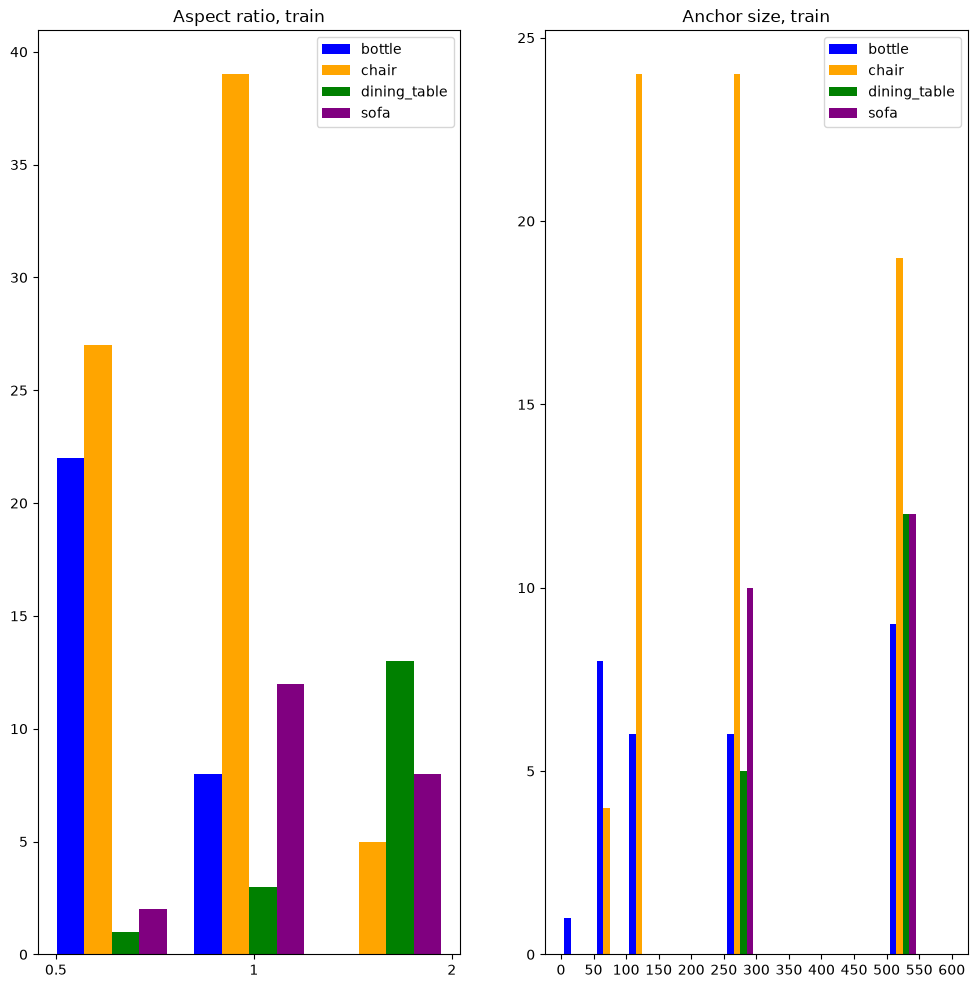

In [20]:
# Inference: extract the selected anchors
model_weights = torch.load(os.path.join(result_dir,'best_model.pth'.format(num_epochs-1)))['state_dict']
model_ft.load_state_dict(model_weights)
[_,_,_,_,_,_,anchors,l_t]=test_detection_model(model_ft, data_loader_test, class_names, 0.5, 0.5, result_dir, False, False, False)

# Anchor statistics
ar=[]
labels=[]
size_anchors=[]
for i in range(anchors.shape[0]):
    labels.append(l_t[i])
    size_anchors.append(np.sqrt((anchors[i,2]-anchors[i,0])*(anchors[i,3]-anchors[i,1])))
    ar.append((anchors[i,2]-anchors[i,0])/(anchors[i,3]-anchors[i,1]))

ar_bins=[0.5,1,2]
log_ar_bins=np.log(ar_bins)
as_bins=np.array([0,50,100,150,200,250,300,350,400,450,500,550,600])

ar=np.array(ar)
log_ar=np.log(ar)
labels=np.array(labels)
size_anchors=np.array(size_anchors)
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12,12))
ax0, ax1 = axes.flatten()
ax0.hist([log_ar[np.where(labels==1)[0]],log_ar[np.where(labels==2)[0]],log_ar[np.where(labels==3)[0]],log_ar[np.where(labels==4)[0]]],
         bins=3,color=['blue','orange','green','purple'],label=class_names[1:])
ax0.legend(prop={'size': 10})
ax0.set_xticks(log_ar_bins)
ax0.set_xticklabels(ar_bins)
ax0.set_title('Aspect ratio, train')
ax1.hist([size_anchors[np.where(labels==1)[0]],size_anchors[np.where(labels==2)[0]],size_anchors[np.where(labels==3)[0]],size_anchors[np.where(labels==4)[0]]],color=['blue','orange','green','purple'],label=class_names[1:], bins=as_bins)
ax1.legend(prop={'size': 10})
ax1.set_title('Anchor size, train')
ax1.set_xticks(as_bins)
ax1.set_xticklabels(as_bins)

Is the distribution of the anchors' sizes and shapes related to those of the bounding boxes provided in training and testing? Justify your answer.

> Answer here

RESOUESTA !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
Yes, the distribution of the selected anchors' sizes and aspect ratios closely mirrors the geometric distributions of the ground-truth bounding boxes, quantized into the discrete set of scales (`32, 64, 128, 256, 512` pixels) and aspect ratios (`0.5, 1.0, 2.0`) generated by the FPN `AnchorGenerator`:

1. **Aspect Ratio Alignment ($W / H$):**
   * **`bottle` (blue):** In both train and test ground-truth distributions, bottles are predominantly tall and narrow ($\text{AR} \le 0.5$, peaking around $0.25\text{–}0.5$). Accordingly, the network selects exclusively vertical and square anchors for `bottle` (**22** detections with $\text{AR} = 0.5$ and **8** with $\text{AR} = 1.0$, and **0** with $\text{AR} = 2.0$).
   * **`chair` (orange):** Ground-truth chairs cluster around $\text{AR} \in [0.5, 1.0]$, which directly matches the selected anchors peaking at $\text{AR} = 1.0$ (**39**) and $\text{AR} = 0.5$ (**27**).
   * **`dining_table` (green) and `sofa` (purple):** Both furniture categories exhibit wide, horizontal ground-truth boxes ($\text{AR} \ge 1.0$, extending from $1.0$ up to $4.0\text{–}7.0$). In response, the RPN assigns predominantly horizontal and square anchors: `dining_table` peaks at $\text{AR} = 2.0$ (**13** vs. **3** at $1.0$ and **1** at $0.5$), while `sofa` concentrates at $\text{AR} = 1.0$ (**12**) and $\text{AR} = 2.0$ (**8**).

2. **Scale / Size Alignment ($\sqrt{W \cdot H}$):**
   * **`bottle`:** Ground-truth bottles concentrate in the smallest size bins ($< 200\text{ px}$), making `bottle` the only class utilizing the smallest FPN anchor levels (**`32`** and **`64`** px, mapped to high-resolution pyramid levels `P2`/`P3`), alongside medium anchors (`128`–`256` px) for foreground bottles.
   * **`chair`:** Spans intermediate ground-truth scales ($100\text{–}500\text{ px}$), matching anchors of size **`128`** (**24**), **`256`** (**24**), and **`512`** (**19**).
   * **`dining_table` and `sofa`:** Ground-truth instances occupy large image areas ($200\text{–}900\text{ px}$). Consequently, both classes rely **exclusively** on the largest anchor scales (**`256`** and **`512`** px, corresponding to the semantically rich, low-resolution `P4`/`P5` pyramid levels), with zero detections at scales `32`, `64`, or `128`.

After analyzing these results, discuss why the library changes the size of the images when these are fed to the network

> Answer here

RESOUESTA !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

`GeneralizedRCNNTransform` resizes input images so that their shortest side is `min_size = 800` pixels (capping the longest side at `max_size = 1333` pixels while preserving the original aspect ratio) for three key architectural reasons:

1. **Preventing spatial collapse of small objects across backbone strides:** Original PASCAL VOC images have a maximum dimension of $\le 500\text{ px}$. Because the ResNet-50 + FPN backbone applies successive spatial subsampling with strides of $4, 8, 16, 32,$ and $64$ (`P2` through `P6`), feeding an unscaled $500\text{ px}$ image would shrink small objects like `bottle` ($30\text{–}60\text{ px}$ originally) down to just $1\text{–}4$ pixels in the feature maps, destroying the local spatial detail needed by the RPN and `RoIAlign` ($7 \times 7$ grid).
2. **Matching object scales to the pre-defined FPN anchor hierarchy:** Faster R-CNN uses fixed anchor base sizes (`32, 64, 128, 256, 512` px) calibrated during COCO pretraining for images in the $800\text{–}1333\text{ px}$ resolution range. Upscaling PASCAL VOC images aligns the dataset's object dimensions with the receptive fields and anchor scales of `P2–P5`.
3. **Preserving aspect ratio and batch compatibility:** Scaling isotropically (computing a single `scale_factor` based on `min_size` and `max_size`) avoids distorting object shapes (preventing a `chair` or `bottle` from being artificially stretched), while standardizing image resolution ranges so feature maps and memory consumption remain predictable during training and inference.

Provide a brief analysis of the visual output of the net, the anchors and the bounding boxes obtained through regression for a given image (you can choose some examples that help you to discuss the results).
  
Does regression work well for all cases? In your opinion, which are the sources of errors?

> Answer here

RESOUESTA !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

#### Visual Analysis of Anchors and Bounding-Box Regression

Using three representative test examples from `instances_pred_0_5` (where **blue** denotes the initial RPN anchor, **red** the final regressed prediction, and **green** the ground truth), we can observe how bounding-box regression behaves across different object scales and scenes:

| Small Scale (`bottle`) | Large Scale (`sofa`) | Complex Scene (`chair` / `sofa`) |
| :---: | :---: | :---: |
| <img src="baseline_results/instances_pred_0_5/64/2008_005399_2.png" width="230"> | <img src="baseline_results/instances_pred_0_5/256/2011_001005_1.png" width="260"> | <img src="baseline_results/instances_pred_0_5/128/2011_002644_4.png" width="260"> |
| `2008_005399_2.png` | `2011_001005_1.png` | `2011_002644_4.png` |

1. **Small-scale vertical adjustment (`2008_005399_2.png` — `bottle`):**
   A small anchor (blue) centered on one of the bottles on the table is accurately stretched vertically by the regressor (red) to match the tall, narrow ground-truth box (green). However, the remaining adjacent bottles in the tightly packed cluster are missed.
2. **Large-scale aspect-ratio adaptation (`2011_001005_1.png` — `sofa`):**
   Even though the selected anchor (blue) is nearly square/tall and covers only the upper-center portion of the sofa, the bounding-box regressor (red) successfully expands it horizontally to capture almost the entire width of the ground-truth sofa (green), with only a slight leftward overshoot onto the coffee table. *(Note: despite accurate spatial regression, the RoI classifier mislabels this box as `chair`).*
3. **Foreground accuracy vs. background clutter (`2011_002644_4.png` — `chair` / `sofa`):**
   For the foreground chair at the bottom center, the blue anchor already aligns closely with the object and the red regressed box refines its boundaries accurately. In contrast, the large foreground sofa, the truncated objects at the image borders, and the small distant white chairs behind the glass door are not detected.

#### Does Regression Work Well in All Cases? Main Sources of Error
No, bounding-box regression does not perform equally well across all scenarios. The primary sources of localization and regression errors observed are:
* **Extreme aspect ratios outside the anchor design (`[0.5, 1.0, 2.0]`):** Very elongated objects (wide sofas/dining tables with $\text{AR} > 3$ or thin bottles with $\text{AR} < 0.3$) require large coordinate offsets from the closest discrete anchor, leading to boundary overshooting or under-segmentation.
* **Object crowding, mutual occlusion, and Non-Maximum Suppression (NMS):** When multiple instances of the same class overlap heavily (such as the row of bottles in `2008_005399_2.png` or chairs tucked under a dining table), feature representations mix and NMS can suppress valid neighboring detections.
* **Truncation at image boundaries and partial visibility:** Objects cut off by the edges of the frame (e.g., the right-side sofa and bottom-left chair in `2011_002644_4.jpg`) lack complete geometric cues, causing the regressor to misestimate their extent or the RPN to assign low objectness scores.
* **Low contrast and small distant instances:** Small objects in cluttered or low-contrast backgrounds (such as the outdoor chairs seen through the reflective glass door in `2011_002644_4.jpg`) produce weak feature activations across FPN levels.

### 4. _RoI pooling_ and classification

In this section, a visual representation of the *RoI pooling* outputs for the different classes will be obtained using the external function `visualize_roipooling`. Furthermore, the classification results will be analyzed. Uncomment the next cell to perform the analysis.

In the following code cell, visual representations of the *RoI pooling* are extracted for each object detected in the `roipool` folder, inside the results folder. The *RoI pooling* outputs a feature map $F_r$ of size $H\times W\times C = 7\times 7\times 2048$. Each representation, in turn, corresponds to a 7x7 cell in which the maximum value of this map $F_r$ is represented over all channels (that is, each element contains the maximum value of all channels for each cell). In this way, the spatial distribution of the activations in the *RoI pooling* can be inferred. Run the following cell and analyze the output representations.

__IMPORTANT__: the mean is not used to extract the representations since in convolutional networks most of the values ​​of the channels in a certain position are usually very low, and this makes that the mean values ​​are very similar.

In [22]:
import sys
del sys.modules['external']
from external import visualize_roipooling

# For the roi-pooling experiment, analyze the top bounding-boxes (th_score>0.7) and only those with
# th_iou>0.7 with the ground-truth
visualize_roipooling(model_ft, data_loader_test, device, class_names, 0.7, 0.7, result_dir, True)

./baseline_results
Evaluating...


Visualize the outputs provided by `visualize_roipooling` (folder roi pooling) and focus on the objects that appear completely in the images.
Can the shape of the object (and perhaps its category) be inferred from the spatial distribution of the RoI pooling? Justify your answer.

> Answer here

RESPUESTA !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
#### Visual Comparison of RGB Crops and $7 \times 7$ RoI Pooling Activations

The table below shows three complete high-confidence detections (`th_score > 0.7`, `th_iou > 0.7`) alongside their corresponding $7 \times 7$ `MultiScaleRoIAlign` activation maps (maximum value across all 256 feature channels per grid cell):

| Class | RGB Detection Crop | $7 \times 7$ RoI Pooling Max-Activation | Spatial Correspondence |
| :---: | :---: | :---: | :--- |
| **`bottle`**<br>(`2008_004659_0_1`) | <img src="baseline_results/roipool/2008_004659_0_1.png" width="110"> | <img src="baseline_results/roipool/2008_004659_0_1_roi.png" width="110"> | High activations concentrate along the central vertical columns (rows 2–6), outlining the cylindrical body and label, while the left and right outer background columns remain dark. |
| **`chair` (side)**<br>(`2008_002521_0_2`) | <img src="baseline_results/roipool/2008_002521_0_2.png" width="115"> | <img src="baseline_results/roipool/2008_002521_0_2_roi.png" width="115"> | Peak activations form an asymmetric "L"-shaped cluster along the left-center vertical backrest and middle seat junction, leaving the upper-right wall background dark. |
| **`chair` (front/3/4)**<br>(`2008_007194_0_2`) | <img src="baseline_results/roipool/2008_007194_0_2.png" width="125"> | <img src="baseline_results/roipool/2008_007194_0_2_roi.png" width="125"> | Activations spread across the upper and middle rows (wide curved backrest and seat cushion) and narrow toward the bottom-center columns where the pedestal stem and metallic base sit. |

#### Can the Object's Shape and Category Be Inferred from the RoI Pooling Distribution?

1. **Inferring Object Shape (Coarse Silhouette): Yes, to a large extent.**
   Because convolutional filters in the ResNet-50 + FPN backbone respond strongly to high-contrast edges, contours, and structural parts while suppressing uniform background regions, projecting the maximum response across channels preserves a **coarse $7 \times 7$ spatial silhouette** of the object. When viewed together with the bounding box's aspect ratio, the bright grid cells clearly follow the vertical central axis of the `bottle`[cite: 44, 45], the backrest-to-seat angle of the wooden `chair`[cite: 42, 43], and the wide upper shell and narrow base of the pedestal `chair`[cite: 46, 47].

2. **Inferring Object Category: Only partially — unreliable from the $7 \times 7$ map alone.**
   While coarse geometry can separate visually distinct shapes (such as a narrow `bottle` from a wide `sofa`), the exact object category **cannot be reliably determined solely from this single-channel $7 \times 7$ representation** for three reasons:
   * **Severe spatial quantization ($7 \times 7$ grid):** Pooling an entire region into only $49$ spatial bins blurs fine-grained structural details (e.g., thin chair legs, bottle caps, or armrests) into coarse blocks.
   * **Loss of channel-wise semantic information:** Taking the maximum across all $256$ feature channels (`np.max(features, axis=1)`) collapses *which* semantic filters were activated (e.g., glass transparency/text filters vs. wood/upholstery textures), preserving only *where* strong features occur.
   * **Viewpoint dependency and background interference:** Comparing the two `chair` maps (`2008_002521_0_2` vs. `2008_007194_0_2`) shows that changing the camera viewpoint drastically alters the 2D activation layout[cite: 42, 43, 46, 47], and strong background edges or specular reflections can also produce bright cells. For this reason, the subsequent fully connected classification head (`TwoMLPHead`) operates on the full $7 \times 7 \times 256 = 12,544$-dimensional tensor rather than a single spatial projection.